In [1]:
import numpy as np
import matplotlib.pyplot as plt
from data.molar_mass import molar_masses as mm
import pandas as pd
import seaborn as sns
import matplotlib

# read filtered data in mol per mol unitd
all_data = pd.read_csv('sample_data_mol_per_mol.csv')
all_samples = all_data['Sample Name'].unique()

# cahnge espanola sample names
change_names = lambda x: x.replace('18-2-', '')

# read data in ppm units
nitric_runs_ppb = pd.read_csv('data/nitric_acid_runs_reduced_ppb.csv')
nitric_runs_ppb['Sample Name'] = nitric_runs_ppb['Sample Name'].apply(change_names)
nitric_runs_ppb = nitric_runs_ppb[nitric_runs_ppb['Sample Name'].isin(all_samples)]




/opt/anaconda3/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [14]:
oxic_seawater, meteoric_fluid

({'C': 29,
  'Ca': 412.00184,
  'Mn': 0.002,
  'Sr': 8,
  'O': 889000.0,
  'Mg': 1295,
  'Ce': 1.8400033120000001e-06,
  'I': 0.047589,
  'd13C': -15,
  'd18O': -30.5,
  'dCe': 0.46,
  'dI': 0.70925},
 {'C': 10,
  'Ca': 80.156,
  'Mn': 0.008,
  'Sr': 0.06,
  'O': 889000.0,
  'Mg': 117.9,
  'Ce': 0.000505,
  'I': 0.03184148264,
  'd13C': -3.245,
  'd18O': -37.7434,
  'dCe': 1.395,
  'dI': 0.70925})

In [25]:
class dotdict(dict):
    """dot.notation access to dictionary attributes"""
    __getattr__ = dict.get
    __setattr__ = dict.__setitem__
    __delattr__ = dict.__delitem__

# Rock and diagenetic fluid compsitions
# Primary aragonite depsited in oxic column
oxic_aragonite = dotdict(dict(
    # concentrations, ppm
    C = 120000,
    Ca = 387500,
    Mn = 0.01, 
    Sr = 10000, 
    O = 480000, 
    Mg = 2500, 
    Ce = np.mean([0.011,0.896]),
    I = 6,
    # isotopes
    d13C = 5, # d13C
    d18O = 0, # d18O PDB
    dCe = 0.67, # Ce anomaly
    dI = 0.70900 # I/Ca ratio
))

# Primary aragonite depsited in anoxic column
anoxic_aragonite = dotdict(dict(
    # concentrations, ppm
    C = 120000,
    Ca = 387500,
    Mn = 1, 
    Sr = 10000, 
    O = 480000, 
    Mg = 2500, 
    Ce = np.mean([0.011,0.896]), # same as oxic
    I = 6,#394500*0.1317*(7.8802e-15*mm['I'])/(0.01028*mm['I']),
    d13C = 5, # d13C
    d18O = 0, # d18O PDB
    dCe = 1.025, # Ce anomaly
    dI = 0.70900  # I/Ca ratio 
))

# Oxic seawater
oxic_seawater = dotdict(dict( # concentrations in ppm
  C = 29, 
  Ca = 0.01028 * mm['Ca'] * 1e3,
  Mn = 2e-3,
  Sr = 8, #0.00009 * mm['Sr'] * 1e3,
  O = 889e3,
  Mg = 1295,
  Ce = 1.3132e-11 * mm['Ce'] * 1e3,
  I = 0.375e-6 * mm['I'] * 1e3,
  d13C = -15, ##1.54, # d13C VPDB
  d18O = -30.5, # d18O, VPDB -- -8 per mil SMOW
  dCe = 0.46, # Ce anomaly
  dI = 0.709250 
  ))

# Reducing seawater
reducing_seawater = dotdict(dict( # concentrations in ppm
  C = 29,
  Ca = 0.01028 * mm['Ca'] * 1e3,
  Mn = 1,
  Sr = 10, # 0.00009 * mm['Sr'] * 1e3, 
  O = 889e3,
  Mg = 1295,
  Ce = 114e-12 * mm['Ce'] * 1e3, 
  I = 1e-9,
  d13C = -1,# np.mean((-25, 5)), # d13C VPDB
  d18O = -30.5, # d18O, VPDB
  dCe = np.mean((0.8, 1.25)), # Ce anomaly
  #dCe = 1.5, # Ce anomaly
  dI = 0.709250  # I/Ca
  ))

# High Ce fluid
high_ce_fluid = dotdict(dict( # concentrations in ppm
  C = 29,
  Ca = 0.01028 * mm['Ca'] * 1e3,
  Mn = 1,
  Sr = 100, # 0.00009 * mm['Sr'] * 1e3, 
  O = 889e3,
  Mg = 1295,
  Ce = 0.2,
  I = 1e-9,
  d13C = -1,# np.mean((-25, 5)), # d13C VPDB
  d18O = -30.5, # d18O, VPDB
  dCe = 1.5, # Ce anomaly
  dI = 0.709250  # I/Ca
  ))

# Meteric seawater
meteoric_fluid = dotdict(dict( # river and/or gw concentrations in ppm
  C = 10,
  Ca = 0.002*mm['Ca'] * 1e3, 
  Mn = 0.008,
  Sr = 0.06, #2.5e-6*mm['Sr'] * 1e3 * 100, 
  O = 889e3,
  Mg = np.mean((0.8, 235)),
  Ce = np.mean((10e-6, 10e-4)),
  I = 2.5091e-7 * mm['I'] * 1e3,
  d13C = -3.245,  # d13C VPDB
  d18O = -37.7434, # d18O, VPDB
  dCe = 1.395, # Ce anomaly
  dI = 0.709250 
  ))

In [27]:
def BannerHanson(rock, fluid):
    '''
    Runs Banner Hanson diagenesis model
    Arguments:
        rock: dict with rock properties
        fluid: doct with diagenetic fluid properties
    Returns:
        rock_evolution: dict with the compositional and isotopic
        evolution of the rock and the fluid
    '''

    # Exchange reaction distribution coefficient (Kd):
    Kd_Sr = 0.025               # Kd Sr-Ca
    Kd_Mn = 5                     # Kd Mn-Ca
    Kd_Ce = np.mean([100,296])
    # Kd_I = 0.0064
    Kd_I = 0.1317
    Kd_C = 1
    Kd_O = 1
    Kd_Ca = 1


    alpha = 1.001
    alpha_O = 1.0102 # 1.03125 # 1.0330
    alpha_Ce = 1.00

    ##
    # Single element distribution coefficient (D):
    CaCO3 = 400000                  # Ca in CaCO3 (ppm)
    Ca_fl = fluid.Ca                     # Ca in fluid
    DJ = CaCO3/Ca_fl 

    D_Sr = DJ*Kd_Sr                  # for Sr
    D_Ca = DJ*Kd_Ca   
    D_Mn = DJ*Kd_Mn                  # for Mn
    D_Ce = DJ*Kd_Ce                  # for Ce
    D_I = DJ*Kd_I 
    D_C = rock.C/fluid.C*Kd_C             # for carbon
    D_O = rock.O/fluid.O*Kd_O         # for oxygen


    F = 0.5 # Weight fraction of fluid

    # Rock evoolution
    re = dotdict(dict(
        Ca = np.zeros(int(1e6)),
        Sr = np.zeros(int(1e6)),
        Mn = np.zeros(int(1e6)),
        Ce = np.zeros(int(1e6)),
        I = np.zeros(int(1e6)),
        C = np.zeros(int(1e6)),
        O = np.zeros(int(1e6)),
        d13C = np.zeros(int(1e6)),
        d18O = np.zeros(int(1e6)),
        dCe = np.zeros(int(1e6)),
        N = np.zeros(int(1e6))
    ))

    # initial concentrations
    re['Sr'][0] = rock['Sr']
    re['Ca'][0] = rock['Ca']
    re['Mn'][0] = rock['Mn']
    re['Ce'][0] = rock['Ce']
    re['I'][0] = rock['I']
    re['C'][0] = rock['C']
    re['O'][0] = rock['O']
    re['N'][0] = 1

    # rock-fluid system
    rs = dotdict(dict(
        Sr = np.zeros(int(1e6)),
        Ca = np.zeros(int(1e6)),
        Mn = np.zeros(int(1e6)),
        Ce = np.zeros(int(1e6)),
        I = np.zeros(int(1e6)),
        C = np.zeros(int(1e6)),
        O = np.zeros(int(1e6)),
        d13C = np.zeros(int(1e6)),
        d18O = np.zeros(int(1e6)),
        dCe = np.zeros(int(1e6)),
    ))

    # fluid
    Cf_Sr = np.zeros(2)
    Cf_Sr[0] = fluid['Sr']
    Cf_Ca = np.zeros(2)
    Cf_Ca[0] = fluid['Ca']
    Cf_Mn = np.zeros(2)
    Cf_Mn[0] = fluid['Mn']
    Cf_Ce = np.zeros(2)
    Cf_Ce[0] = fluid['Ce']
    Cf_I = np.zeros(2)
    Cf_I[0] = fluid['I']
    Cf_C = np.zeros(2)
    Cf_C[0] = fluid['C']
    Cf_O = np.zeros(2)
    Cf_O[0] = fluid['O']
    d13C_f = fluid['d13C']
    d18O_f = fluid['d18O']
    dCe_f = fluid['dCe']


    rs.Sr[0] = F*Cf_Sr[0] + (1 - F)*re.Sr[0] 
    rs.Ca[0] = F*Cf_Ca[0] + (1 - F)*re.Ca[0] 
    rs.Mn[0] = F*Cf_Mn[0] + (1 - F)*re.Mn[0] 
    rs.Ce[0] = F*Cf_Ce[0] + (1 - F)*re.Ce[0] 
    rs.I[0] = F*Cf_I[0] + (1 - F)*re.I[0] 
    rs.C[0] = F*Cf_C[0] + (1 - F)*re.C[0] 
    rs.O[0] = F*Cf_O[0] + (1 - F)*re.O[0]

    # Initial isotopes of the system:
    re.d13C[0] = rock['d13C']
    re.d18O[0] = rock['d18O']
    re.dCe[0] = rock['dCe']

    rs.d13C[0] = (d13C_f*Cf_C[0]*F + re.d13C[0]*re.C[0]*(1 - F))/rs.C[0] 
    rs.d18O[0] = (d18O_f*Cf_O[0]*F + re.d18O[0]*re.O[0]*(1 - F))/rs.O[0] 
    rs.dCe[0]  = (dCe_f*Cf_Ce[0]*F + re.dCe[0]*re.Ce[0]*(1 - F))/rs.Ce[0] 

    ##
    # Closed-system equilibration:

    # Partitioning Sr into the rock:
    re.Sr[1] = rs.Sr[0]/(F/D_Sr + (1 - F)) 
    re.Ca[1] = rs.Ca[0]/(F/D_Ca + (1 - F)) 
    re.Mn[1] = rs.Mn[0]/(F/D_Mn + (1 - F)) 
    re.Ce[1] = rs.Ce[0]/(F/D_Ce + (1 - F)) 
    re.I[1] = rs.I[0]/(F/D_I + (1 - F)) 
    re.C[1] = rs.C[0]/(F/D_C + (1 - F)) 
    re.O[1] = rs.O[0]/(F/D_O + (1 - F)) 

    # Partitioning into the fluid:
    Cf_Sr[1] = re.Sr[1]/D_Sr 
    Cf_Ca[1] = re.Ca[1]/D_Ca 
    Cf_Mn[1] = re.Mn[1]/D_Mn
    Cf_Ce[1] = re.Ce[1]/D_Ce 
    Cf_I[1] = re.I[1]/D_I 
    Cf_C[1] = re.C[1]/D_C 
    Cf_O[1] = re.O[1]/D_O 

    # Check for mass balance:
    rs.Sr[1] = F*Cf_Sr[1] + (1 - F)*re.Sr[1] 
    rs.Ca[1] = F*Cf_Ca[1] + (1 - F)*re.Ca[1] 
    rs.Mn[1] = F*Cf_Mn[1] + (1 - F)*re.Mn[1] 
    rs.Ce[1] = F*Cf_Ce[1] + (1 - F)*re.Ce[1] 
    rs.I[1] = F*Cf_I[1] + (1 - F)*re.I[1] 
    rs.C[1] = F*Cf_C[1] + (1 - F)*re.C[1] 
    rs.O[1] = F*Cf_O[1] + (1 - F)*re.O[1] 

    # step 2 isotopes of the system:
    re.d13C[1] = (rs.d13C[0]*rs.C[1] - F*d13C_f*Cf_C[1])/((1 - F)*re.C[1]) 
    rs.d13C[1] = (d13C_f*Cf_C[1]*F + re.d13C[1]*re.C[1]*(1 - F))/rs.C[1] 

    re.d18O[1] = (rs.d18O[0]*rs.O[1] - F*d18O_f*Cf_O[1])/((1 - F)*re.O[1]) 
    rs.d18O[1] = (d18O_f*Cf_O[1]*F + re.d18O[1]*re.O[1]*(1 - F))/rs.O[1] 

    re.dCe[1] = (rs.dCe[0]*rs.Ce[1] - F*dCe_f*Cf_Ce[1])/((1 - F)*re.Ce[1]) 
    rs.dCe[1] = (dCe_f*Cf_Ce[1]*F + re.dCe[1]*re.Ce[1]*(1 - F))/rs.Ce[1] 


    ##

    # Open-system equilibration (Cf_I does not change!):
    for i in range(1, int(1e6)):

        # partitioning into the rock:
        re.Sr[i] = rs.Sr[i-1]/(F/D_Sr + (1 - F)) 
        re.Ca[i] = rs.Ca[i-1]/(F/D_Ca + (1 - F)) 
        re.Mn[i] = rs.Mn[i-1]/(F/D_Mn + (1 - F))
        re.Ce[i] = rs.Ce[i-1]/(F/D_Ce + (1 - F)) 
        re.I[i] = rs.I[i-1]/(F/D_I + (1 - F)) 
        re.C[i] = rs.C[i-1]/(F/D_C + (1 - F)) 
        re.O[i] = rs.O[i-1]/(F/D_O + (1 - F)) 

        # calculate new mass of system:
        rs.Sr[i] = F*Cf_Sr[0] + (1 - F)*re.Sr[i] 
        rs.Ca[i] = F*Cf_Ca[0] + (1 - F)*re.Ca[i] 
        rs.Mn[i] = F*Cf_Mn[0] + (1 - F)*re.Mn[i]
        rs.Ce[i] = F*Cf_Ce[0] + (1 - F)*re.Ce[i] 
        rs.I[i] = F*Cf_I[0] + (1 - F)*re.I[i] 
        rs.C[i] = F*Cf_C[0] + (1 - F)*re.C[i] 
        rs.O[i] = F*Cf_O[0] + (1 - F)*re.O[i] 

        # isotopes:
        #rs.d13C[i] = rs.d13C[i-1]                       # no fractionations
        #rs.d18O[i] = rs.d18O[i-1] 

        # with fractionation
        re.d13C[i] = (rs.d13C[i-1]*rs.C[i]*alpha - F*Cf_C[1]*1000*(1-alpha))/\
            (F*Cf_C[1] + alpha*(1-F)*re.C[i]) 

        rs.d13C[i] = (d13C_f*Cf_C[1]*F + re.d13C[i]*re.C[i]*(1 - F))/rs.C[i] 


        re.d18O[i] = (rs.d18O[i-1]*rs.O[i]*alpha_O - F*Cf_O[1]*1000*(1-alpha_O))/\
            (F*Cf_O[1] + alpha_O*(1-F)*re.O[i]) 

        rs.d18O[i] = (d18O_f*Cf_O[1]*F + re.d18O[i]*re.O[i]*(1 - F))/rs.O[i]

        re.dCe[i] = (rs.dCe[i-1]*rs.Ce[i]*alpha_Ce - F*Cf_Ce[1]*1000*(1-alpha_Ce))/\
            (F*Cf_Ce[1] + alpha_Ce*(1-F)*re.Ce[i]) 
    
        rs.dCe[i] = (dCe_f*Cf_Ce[1]*F + re.dCe[i]*re.Ce[i]*(1 - F))/rs.Ce[i] 

        # cummulative fluid:rock ratio
        re.N[i] = i*F/(1-F) 
        
    return re, rs


re_mtfl, rs_mtfl = BannerHanson(rock=oxic_aragonite, fluid=meteoric_fluid)
re_oxsw, rs_oxsw = BannerHanson(rock=oxic_aragonite, fluid=oxic_seawater)
re_rdsw, rs_rdsw = BannerHanson(rock=oxic_aragonite, fluid=reducing_seawater)
re_hcf, rs_hcf = BannerHanson(rock=oxic_aragonite, fluid=high_ce_fluid)


/var/folders/5v/vrzl4plx1598hr5q_5ssvl3r0000gn/T/ipykernel_74354/3186514819.py:293: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.draw()
/var/folders/5v/vrzl4plx1598hr5q_5ssvl3r0000gn/T/ipykernel_74354/3186514819.py:299: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig('plots/BannerHanson_model.pdf', bbox_inches='tight')
/var/folders/5v/vrzl4plx1598hr5q_5ssvl3r0000gn/T/ipykernel_74354/3186514819.py:299: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig('plots/BannerHanson_model.pdf', bbox_inches='tight')
/opt/anaconda3/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


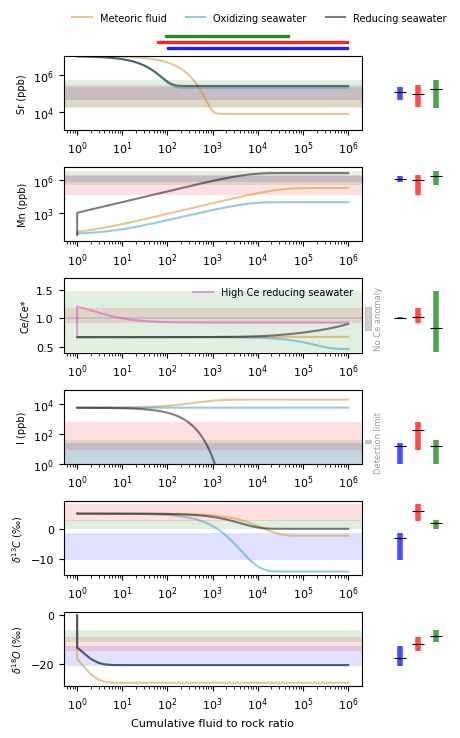

In [28]:
# plot mode results
a4_x, a4_y = (8.27, 11.69)

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

matplotlib.rc('xtick', labelsize=8)
matplotlib.rc('ytick', labelsize=8)

# ==========================================================
# Shared extent definitions (USED EVERYWHERE)
# ==========================================================
extent_ranges = [(90, 0.5e5), (60, 1e6), (100, 1e6)]
extent_colors = ['green', 'red', 'blue']

# ==========================================================
# Helper functions
# ==========================================================
def formation_extent_bars_with_mean(
    ax, data, ycol, groupcol='formation',
    colors=('b','r','g'), width_frac=0.2
):
    groups = sorted(data[groupcol].unique())
    x_positions = np.linspace(0.2, 0.8, len(groups))
    
    for formation, color, xpos in zip(groups, colors, x_positions):
        vals = data[data[groupcol] == formation][ycol].dropna()
        if ax.get_yscale() == 'log':
            vals = vals[vals > 0]
        if len(vals) == 0:
            continue
        
        y_min, y_max = vals.min(), vals.max()
        y_mean = vals.mean()
        
        ax.vlines(x=xpos, ymin=y_min, ymax=y_max, color=color, lw=4, alpha=0.7)
        ax.hlines(y=y_mean, xmin=xpos-width_frac/2, xmax=xpos+width_frac/2,
                  color='k', lw=0.8)
    
    ax.set_xlim(0, 1)
    ax.axis('off')

def formation_horizontal_extent_shading(
    ax, data, ycol, groupcol='formation',
    colors=('b','r','g'), alpha=0.12, zorder=0
):
    groups = sorted(data[groupcol].unique())
    for formation, color in zip(groups, colors):
        vals = data[data[groupcol] == formation][ycol].dropna()
        if ax.get_yscale() == 'log':
            vals = vals[vals > 0]
        if len(vals) == 0:
            continue
        ax.axhspan(vals.min(), vals.max(),
                   facecolor=color, alpha=alpha, zorder=zorder)

def extent_bars_above_axis(
    ax, x_ranges, y_top=1.5, height=0.02, dy=0.06,
    colors=None, alpha=0.4
):
    if colors is None:
        colors = ['k'] * len(x_ranges)

    xlim = ax.get_xlim()

    for i, ((x1, x2), color) in enumerate(zip(x_ranges, colors)):
        y = y_top - i * dy

        xa = (np.log10(x1) - np.log10(xlim[0])) / (np.log10(xlim[1]) - np.log10(xlim[0]))
        xb = (np.log10(x2) - np.log10(xlim[0])) / (np.log10(xlim[1]) - np.log10(xlim[0]))

        ax.add_patch(
            plt.Rectangle(
                (xa, y), xb - xa, height,
                transform=ax.transAxes,
                facecolor=color,
                edgecolor=color,
                alpha=alpha,
                clip_on=False
            )
        )

def vertical_y_range_bar_outside(
    ax, y1, y2,
    label=None,
    x_left=1.01, width=0.02,
    color='gray', alpha=0.35,
    label_offset=0.01, label_size=6
):
    """
    Vertical bar outside axis spanning y1–y2 (data coords),
    with optional vertical label.
    """
    ylim = ax.get_ylim()

    if ax.get_yscale() == 'log':
        ya = (np.log10(y1) - np.log10(ylim[0])) / (np.log10(ylim[1]) - np.log10(ylim[0]))
        yb = (np.log10(y2) - np.log10(ylim[0])) / (np.log10(ylim[1]) - np.log10(ylim[0]))
    else:
        ya = (y1 - ylim[0]) / (ylim[1] - ylim[0])
        yb = (y2 - ylim[0]) / (ylim[1] - ylim[0])

    # bar
    ax.add_patch(
        plt.Rectangle(
            (x_left, ya),
            width,
            yb - ya,
            transform=ax.transAxes,
            facecolor=color,
            edgecolor=color,
            alpha=alpha,
            clip_on=False
        )
    )

    # label
    if label is not None:
        ax.text(
            x_left + width + label_offset,
            0.5 * (ya + yb),
            label,
            transform=ax.transAxes,
            rotation=90,
            va='center',
            ha='left',
            fontsize=label_size,
            color=color,
            alpha=0.8,
            clip_on=False
        )

# ==========================================================
# Figure
# ==========================================================
fig, axs = plt.subplots(
    6, 2,
    figsize=[a4_x * 0.6, a4_y * 0.7],
    gridspec_kw={'width_ratios': [5, 1]},
    sharey='row'
)

# -------------------------
# Sr
# -------------------------
ax = axs[0][0]
ax.plot(re_mtfl.N, re_mtfl.Sr * 1e3, color='#CF8F27', alpha=0.5, label='Meteoric fluid')
ax.plot(re_oxsw.N, re_oxsw.Sr * 1e3, color='#3396CC', alpha=0.5, label='Oxidizing seawater')
ax.plot(re_rdsw.N, re_rdsw.Sr * 1e3, color='k', alpha=0.5, label='Reducing seawater')

ax.set_ylabel('Sr (ppb)', fontsize=7)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(1e3, 1e7)

ax.legend(fontsize=7, frameon=False, ncol=3,
          loc='upper left', bbox_to_anchor=(0, 1.7))

extent_bars_above_axis(ax, extent_ranges,
                       y_top=1.25, height=0.03, dy=0.08,
                       colors=extent_colors, alpha=0.8)

formation_horizontal_extent_shading(
    ax, nitric_runs_ppb, '88  Sr  [ No Gas ]'
)

axs[0][1].set_yscale('log')
formation_extent_bars_with_mean(
    axs[0][1], nitric_runs_ppb, '88  Sr  [ No Gas ]'
)

# -------------------------
# Mn
# -------------------------
ax = axs[1][0]
ax.plot(re_mtfl.N, re_mtfl.Mn * 1e3, color='#CF8F27', alpha=0.5)
ax.plot(re_oxsw.N, re_oxsw.Mn * 1e3, color='#3396CC', alpha=0.5)
ax.plot(re_rdsw.N, re_rdsw.Mn * 1e3, color='k', alpha=0.5)

ax.set_ylabel('Mn (ppb)', fontsize=7)
ax.set_xscale('log')
ax.set_yscale('log')

formation_horizontal_extent_shading(
    ax, nitric_runs_ppb, '55 -> 55  Mn  [ H2 ]'
)

axs[1][1].set_yscale('log')
formation_extent_bars_with_mean(
    axs[1][1], nitric_runs_ppb, '55 -> 55  Mn  [ H2 ]'
)

# -------------------------
# Ce anomaly
# -------------------------
ax = axs[2][0]
ax.plot(re_mtfl.N, re_mtfl.dCe, color='#CF8F27', alpha=0.5)
ax.plot(re_oxsw.N, re_oxsw.dCe, color='#3396CC', alpha=0.5)
ax.plot(re_rdsw.N, re_rdsw.dCe, color='k', alpha=0.5)
ax.plot(re_hcf.N, re_hcf.dCe, color='#E916CB', alpha=0.4, label='High Ce reducing seawater')

ax.set_ylabel(r'Ce/Ce*', fontsize=7)
ax.set_xscale('log')
ax.set_ylim(0.4, 1.7)

# legend retained (semantic)
ax.legend(fontsize=7, frameon=False)

vertical_y_range_bar_outside(ax, 0.8, 1.2, label='No Ce anomaly')

formation_horizontal_extent_shading(
    ax, all_data, 'Ce_anomaly_geom'
)

formation_extent_bars_with_mean(
    axs[2][1], all_data, 'Ce_anomaly_geom'
)

# -------------------------
# I
# -------------------------
ax = axs[3][0]
ax.plot(re_mtfl.N, re_mtfl.I * 1e3, color='#CF8F27', alpha=0.5)
ax.plot(re_oxsw.N, re_oxsw.I * 1e3, color='#3396CC', alpha=0.5)
ax.plot(re_rdsw.N, re_rdsw.I * 1e3, color='k', alpha=0.5)

ax.set_ylabel('I (ppb)', fontsize=7)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(1, 1e5)

I_detection_min = 6e-3 * 4000
I_detection_max = 1e-2 * 4000

vertical_y_range_bar_outside(
    ax, I_detection_min, I_detection_max, label='Detection limit'
)

formation_horizontal_extent_shading(
    ax, nitric_runs_ppb, '127  I  [ No Gas ]'
)

axs[3][1].set_yscale('log')
formation_extent_bars_with_mean(
    axs[3][1], nitric_runs_ppb, '127  I  [ No Gas ]'
)

# -------------------------
# d13C
# -------------------------
ax = axs[4][0]
ax.plot(re_mtfl.N, re_mtfl.d13C, color='#CF8F27', alpha=0.5)
ax.plot(re_oxsw.N, re_oxsw.d13C, color='#3396CC', alpha=0.5)
ax.plot(re_rdsw.N, re_rdsw.d13C, color='k', alpha=0.5)

ax.set_ylabel(r'$\delta^{13}C$ (‰)', fontsize=7)
ax.set_xscale('log')

formation_horizontal_extent_shading(
    ax, all_data, 'd13c_sp'
)

formation_extent_bars_with_mean(
    axs[4][1], all_data, 'd13c_sp'
)

# -------------------------
# d18O
# -------------------------
ax = axs[5][0]
ax.plot(re_mtfl.N, re_mtfl.d18O, color='#CF8F27', alpha=0.5)
ax.plot(re_oxsw.N, re_oxsw.d18O, color='#3396CC', alpha=0.5)
ax.plot(re_rdsw.N, re_rdsw.d18O, color='k', alpha=0.5)

ax.set_ylabel(r'$\delta^{18}O$ (‰)', fontsize=7)
ax.set_xlabel('Cumulative fluid to rock ratio', fontsize=8)
ax.set_xscale('log')

formation_horizontal_extent_shading(
    ax, all_data, 'd18o_sp'
)

formation_extent_bars_with_mean(
    axs[5][1], all_data, 'd18o_sp'
)
axs[5][1].set_xlabel('Extent', fontsize=8)

# ==========================================================
# Sync y-axis for both columns
# ==========================================================
fig.canvas.draw()
for i in range(6):
    ymin, ymax = axs[i][0].get_ylim()
    axs[i][1].set_ylim(ymin, ymax)

plt.subplots_adjust(wspace=0.15, hspace=0.5)
plt.savefig('plots/BannerHanson_model.pdf', bbox_inches='tight')
# plt.close()




(0.1, 10000.0)

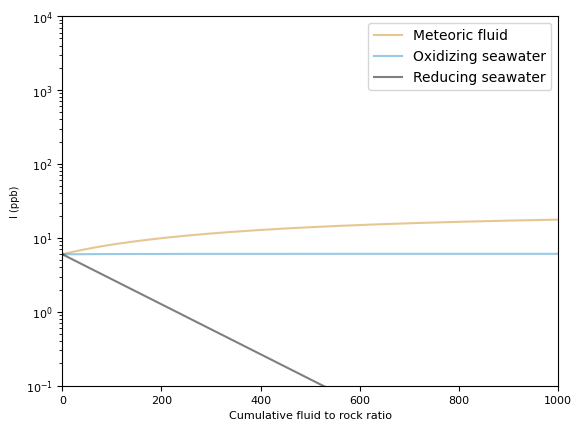

In [12]:
plt.plot(re_mtfl.N, re_mtfl.I, color='#CF8F27', alpha=0.5, label='Meteoric fluid')
plt.plot(re_oxsw.N, re_oxsw.I, color='#3396CC', alpha=0.5, label='Oxidizing seawater')
plt.plot(re_rdsw.N, re_rdsw.I, color='k', alpha=0.5, label='Reducing seawater')
plt.ylabel('I (ppb)', fontsize=7)
plt.xlabel('Cumulative fluid to rock ratio', fontsize=8)
plt.xlim(0, 1000)
plt.legend()
plt.yscale('log')
plt.ylim(0.1, 1e4)

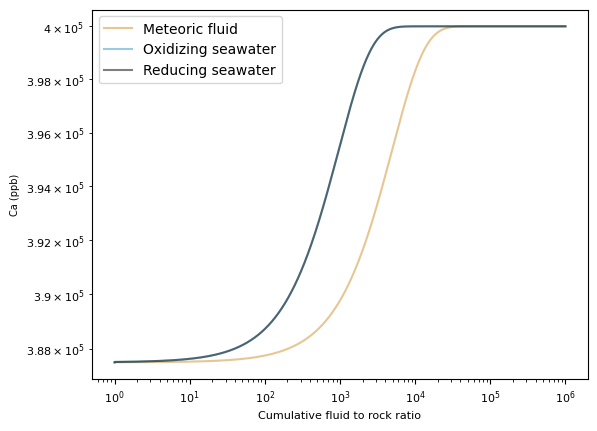

In [5]:
plt.plot(re_mtfl.N, re_mtfl.Ca, color='#CF8F27', alpha=0.5, label='Meteoric fluid')
plt.plot(re_oxsw.N, re_oxsw.Ca, color='#3396CC', alpha=0.5, label='Oxidizing seawater')
plt.plot(re_rdsw.N, re_rdsw.Ca, color='k', alpha=0.5, label='Reducing seawater')
plt.ylabel('Ca (ppb)', fontsize=7)
plt.xlabel('Cumulative fluid to rock ratio', fontsize=8)
plt.xscale('log')
plt.yscale('log')
plt.legend()

In [6]:
oxic_aragonite

{'C': 120000,
 'Ca': 387500,
 'Mn': 0.01,
 'Sr': 10000,
 'O': 480000,
 'Mg': 2500,
 'Ce': 0.4535,
 'I': 6,
 'd13C': 5,
 'd18O': 0,
 'dCe': 0.67,
 'dI': 0.709}

NameError: name 're_mtflCe' is not defined

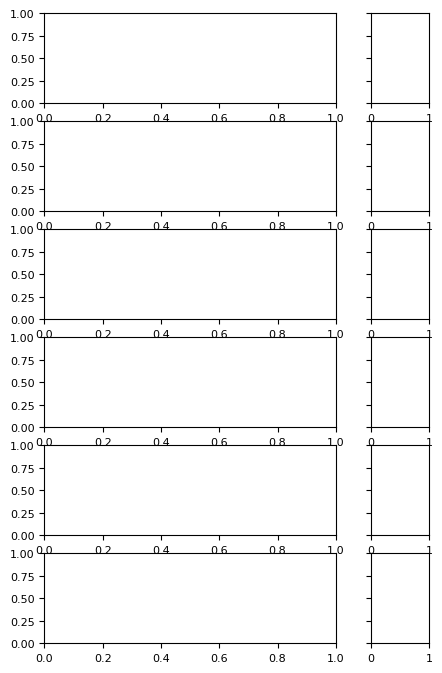

In [7]:
# plot mode results
a4_x, a4_y = (8.27, 11.69)

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

matplotlib.rc('xtick', labelsize=8)
matplotlib.rc('ytick', labelsize=8)

# ==========================================================
# Shared extent definitions (USED EVERYWHERE)
# ==========================================================
extent_ranges = [(90, 0.5e5), (60, 1e6), (100, 1e6)]
extent_colors = ['green', 'red', 'blue']

# ==========================================================
# Helper functions
# ==========================================================
def formation_extent_bars_with_mean(
    ax, data, ycol, groupcol='formation',
    colors=('b','r','g'), width_frac=0.2
):
    groups = sorted(data[groupcol].unique())
    x_positions = np.linspace(0.2, 0.8, len(groups))
    
    for formation, color, xpos in zip(groups, colors, x_positions):
        vals = data[data[groupcol] == formation][ycol].dropna()
        if ax.get_yscale() == 'log':
            vals = vals[vals > 0]
        if len(vals) == 0:
            continue
        
        y_min, y_max = vals.min(), vals.max()
        y_mean = vals.mean()
        
        ax.vlines(x=xpos, ymin=y_min, ymax=y_max, color=color, lw=4, alpha=0.7)
        ax.hlines(y=y_mean, xmin=xpos-width_frac/2, xmax=xpos+width_frac/2,
                  color='k', lw=0.8)
    
    ax.set_xlim(0, 1)
    ax.axis('off')

def formation_horizontal_extent_shading(
    ax, data, ycol, groupcol='formation',
    colors=('b','r','g'), alpha=0.12, zorder=0
):
    groups = sorted(data[groupcol].unique())
    for formation, color in zip(groups, colors):
        vals = data[data[groupcol] == formation][ycol].dropna()
        if ax.get_yscale() == 'log':
            vals = vals[vals > 0]
        if len(vals) == 0:
            continue
        ax.axhspan(vals.min(), vals.max(),
                   facecolor=color, alpha=alpha, zorder=zorder)

def extent_bars_above_axis(
    ax, x_ranges, y_top=1.5, height=0.02, dy=0.06,
    colors=None, alpha=0.4
):
    if colors is None:
        colors = ['k'] * len(x_ranges)

    xlim = ax.get_xlim()

    for i, ((x1, x2), color) in enumerate(zip(x_ranges, colors)):
        y = y_top - i * dy

        xa = (np.log10(x1) - np.log10(xlim[0])) / (np.log10(xlim[1]) - np.log10(xlim[0]))
        xb = (np.log10(x2) - np.log10(xlim[0])) / (np.log10(xlim[1]) - np.log10(xlim[0]))

        ax.add_patch(
            plt.Rectangle(
                (xa, y), xb - xa, height,
                transform=ax.transAxes,
                facecolor=color,
                edgecolor=color,
                alpha=alpha,
                clip_on=False
            )
        )

def vertical_y_range_bar_outside(
    ax, y1, y2,
    label=None,
    x_left=1.01, width=0.02,
    color='gray', alpha=0.35,
    label_offset=0.01, label_size=6
):
    """
    Vertical bar outside axis spanning y1–y2 (data coords),
    with optional vertical label.
    """
    ylim = ax.get_ylim()

    if ax.get_yscale() == 'log':
        ya = (np.log10(y1) - np.log10(ylim[0])) / (np.log10(ylim[1]) - np.log10(ylim[0]))
        yb = (np.log10(y2) - np.log10(ylim[0])) / (np.log10(ylim[1]) - np.log10(ylim[0]))
    else:
        ya = (y1 - ylim[0]) / (ylim[1] - ylim[0])
        yb = (y2 - ylim[0]) / (ylim[1] - ylim[0])

    # bar
    ax.add_patch(
        plt.Rectangle(
            (x_left, ya),
            width,
            yb - ya,
            transform=ax.transAxes,
            facecolor=color,
            edgecolor=color,
            alpha=alpha,
            clip_on=False
        )
    )

    # label
    if label is not None:
        ax.text(
            x_left + width + label_offset,
            0.5 * (ya + yb),
            label,
            transform=ax.transAxes,
            rotation=90,
            va='center',
            ha='left',
            fontsize=label_size,
            color=color,
            alpha=0.8,
            clip_on=False
        )

# ==========================================================
# Figure
# ==========================================================
fig, axs = plt.subplots(
    6, 2,
    figsize=[a4_x * 0.6, a4_y * 0.7],
    gridspec_kw={'width_ratios': [5, 1]},
    sharey='row'
)

# -------------------------
# Sr
# -------------------------
ax = axs[0][0]
ax.plot(re_mtflCe.N, re_mtflCe.Sr * 1e3, color='k', alpha=0.5, label='Meteoric fluid')

ax.set_ylabel('Sr (ppb)', fontsize=7)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(1e3, 1e7)

ax.legend(fontsize=7, frameon=False, ncol=3,
          loc='upper left', bbox_to_anchor=(0, 1.7))

extent_bars_above_axis(ax, extent_ranges,
                       y_top=1.25, height=0.03, dy=0.08,
                       colors=extent_colors, alpha=0.8)

formation_horizontal_extent_shading(
    ax, nitric_runs_ppb, '88  Sr  [ No Gas ]'
)

axs[0][1].set_yscale('log')
formation_extent_bars_with_mean(
    axs[0][1], nitric_runs_ppb, '88  Sr  [ No Gas ]'
)

# -------------------------
# Mn
# -------------------------
ax = axs[1][0]
ax.plot(re_mtflCe.N, re_mtflCe.Mn * 1e3, color='k', alpha=0.5)

ax.set_ylabel('Mn (ppb)', fontsize=7)
ax.set_xscale('log')
ax.set_yscale('log')

formation_horizontal_extent_shading(
    ax, nitric_runs_ppb, '55 -> 55  Mn  [ H2 ]'
)

axs[1][1].set_yscale('log')
formation_extent_bars_with_mean(
    axs[1][1], nitric_runs_ppb, '55 -> 55  Mn  [ H2 ]'
)

# -------------------------
# Ce anomaly
# -------------------------
ax = axs[2][0]
ax.plot(re_mtflCe.N, re_mtflCe.dCe, color='k', alpha=0.5)

ax.set_ylabel(r'Ce/Ce*', fontsize=7)
ax.set_xscale('log')
ax.set_ylim(0.4, 1.7)

# legend retained (semantic)
ax.legend(fontsize=7, frameon=False)

vertical_y_range_bar_outside(ax, 0.8, 1.2, label='No Ce anomaly')

formation_horizontal_extent_shading(
    ax, all_data, 'Ce_anomaly_geom'
)

formation_extent_bars_with_mean(
    axs[2][1], all_data, 'Ce_anomaly_geom'
)

# -------------------------
# I
# -------------------------
ax = axs[3][0]
ax.plot(re_mtflCe.N, re_mtflCe.I * 1e3, color='k', alpha=0.5)

ax.set_ylabel('I (ppb)', fontsize=7)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(1, 1e4)

I_detection_min = 6e-3 * 4000
I_detection_max = 1e-2 * 4000

vertical_y_range_bar_outside(
    ax, I_detection_min, I_detection_max, label='Detection limit'
)

formation_horizontal_extent_shading(
    ax, nitric_runs_ppb, '127  I  [ No Gas ]'
)

axs[3][1].set_yscale('log')
formation_extent_bars_with_mean(
    axs[3][1], nitric_runs_ppb, '127  I  [ No Gas ]'
)

# -------------------------
# d13C
# -------------------------
ax = axs[4][0]
ax.plot(re_mtflCe.N, re_mtflCe.d13C, color='k', alpha=0.5)
ax.set_ylabel(r'$\delta^{13}C$ (‰)', fontsize=7)
ax.set_xscale('log')

formation_horizontal_extent_shading(
    ax, all_data, 'd13c_sp'
)

formation_extent_bars_with_mean(
    axs[4][1], all_data, 'd13c_sp'
)

# -------------------------
# d18O
# -------------------------
ax = axs[5][0]
ax.plot(re_mtflCe.N, re_mtflCe.d18O, color='k', alpha=0.5)

ax.set_ylabel(r'$\delta^{18}O$ (‰)', fontsize=7)
ax.set_xlabel('Cumulative fluid to rock ratio', fontsize=8)
ax.set_xscale('log')

formation_horizontal_extent_shading(
    ax, all_data, 'd18o_sp'
)

formation_extent_bars_with_mean(
    axs[5][1], all_data, 'd18o_sp'
)
axs[5][1].set_xlabel('Extent', fontsize=8)

# ==========================================================
# Sync y-axis for both columns
# ==========================================================
fig.canvas.draw()
for i in range(6):
    ymin, ymax = axs[i][0].get_ylim()
    axs[i][1].set_ylim(ymin, ymax)

plt.subplots_adjust(wspace=0.15, hspace=0.5)
plt.savefig('plots/BannerHanson_model.pdf', bbox_inches='tight')
# plt.close()




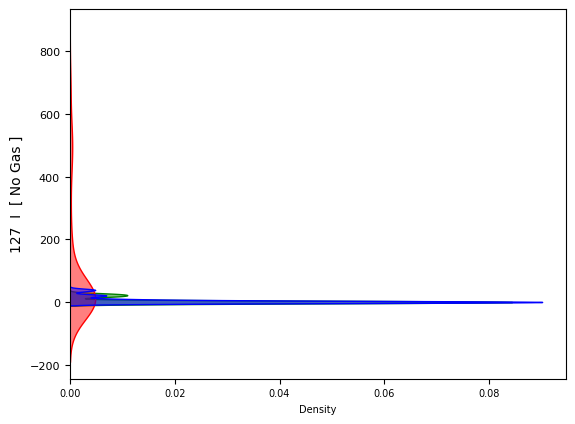

In [ ]:
def formation_density_kdes(
    ax, data, ycol, groupcol='formation',
    colors=('green', 'red', 'blue'),
    bw_adjust=0.8, alpha=0.5, log_scale=False
):
    """
    Horizontal KDEs:
    y-axis = concentration
    x-axis = probability density
    Works with log-scaled y-axis.
    """
    groups = sorted(data[groupcol].unique())

    for formation, color in zip(groups, colors):
        vals = data.loc[data[groupcol] == formation, ycol].dropna()

        # Log-safe filtering
        if ax.get_yscale() == 'log':
            vals = vals[vals > 0]

        if len(vals) < 5:
            continue  # KDEs need some data

        sns.kdeplot(
            y=vals,
            ax=ax,
            bw_adjust=bw_adjust,
            fill=True,
            color=color,
            alpha=alpha,
            linewidth=1,
            log_scale=log_scale
        )

    ax.set_xlabel('Density', fontsize=7)
    ax.tick_params(axis='x', labelsize=7)
    ax.set_xlim(left=0)

fig, axs = plt.subplots(1,1)
formation_density_kdes(axs, nitric_runs_ppb, '127  I  [ No Gas ]', log_scale=False)

In [ ]:
nitric_runs_ppb[nitric_runs_ppb.formation=='Steep Rock']['88  Sr  [ No Gas ]'].to_numpy()

array([432358.19547037, 267623.39104896, 263544.81254169, 236303.08346489,
       356594.17944065, 293840.40509129, 411924.50808956, 228197.58181581,
       242929.26155926, 310037.00491793, 281285.56477063, 264932.60168161,
       259632.83521158, 291870.8509378 , 384268.11445315,  48281.144449  ,
       201070.31532733,  44117.31328187, 483773.52683011, 336097.91924679,
       365840.2590991 , 296406.75186416,  54854.95186017,  47888.52427685,
        50983.16180642, 180725.66319505, 332712.33154495,  59893.23650839,
       117824.71601291, 108523.9821471 ,  20626.01702859,  22432.06239249,
        25404.72366765,  25590.76563516,  26060.60851244,  19777.66118588,
        24762.61819659,  19424.74142458,  25528.80787097,  21882.23552826,
        18782.47600773,  19386.19827657,  16276.62348158,  62228.91423614,
        79067.28533672,  86455.17082213, 119715.69369075, 128533.16680409,
        82344.13477702,  65534.63699366,  83104.46075065,  46514.93120775,
       116887.71273835, 1

<Axes: xlabel='55 -> 55  Mn  [ H2 ]', ylabel='Density'>

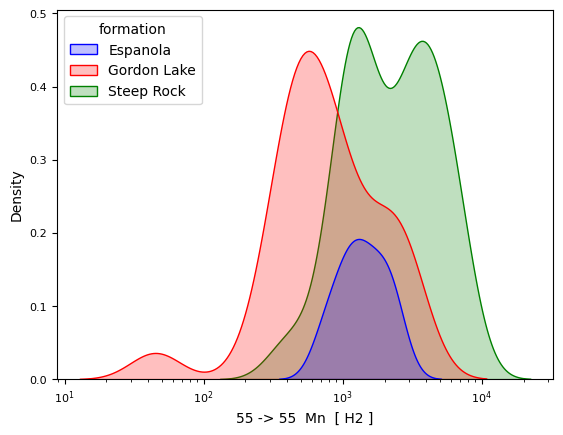

In [ ]:
# 88  Sr  [ No Gas ]

sns.kdeplot(nitric_runs_ppb[nitric_runs_ppb['55 -> 55  Mn  [ H2 ]']>0],
    x=nitric_runs_ppb['55 -> 55  Mn  [ H2 ]']/1e3, 
    hue='formation', fill=True, 
    palette=['b', 'r', 'g'], log_scale=True)